# DSCI 552 — Homework 8

**Name:** Khushi Patel  
**GitHub Username:** khushigi-a11y  
**USC ID:** 4163615025

In [1]:
import warnings
warnings.simplefilter("ignore")

import time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from joblib import Parallel, delayed

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC, SVC
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve, confusion_matrix, zero_one_loss
)


### 1(a) Breast Cancer Wisconsin (Diagnostic) Dataset

In [2]:
df = pd.read_csv("../data/wdbc.data", header=None)

print("Dataset shape:", df.shape)
print("Class distribution:")
print(df[1].value_counts())

df.head()

Dataset shape: (569, 32)
Class distribution:
1
B    357
M    212
Name: count, dtype: int64


,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### (b) Monte Carlo Simulation
#### i. Supervised Learning — L1-Penalized SVM

In [3]:
X = df.iloc[:, 2:]
y = (df.iloc[:, 1] == "M").astype(int)

results = []
roc_data = None

for i in range(30):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=i
    )

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
      ("svm", LinearSVC(
    penalty="l1",
    dual=False,
    max_iter=100000,
    tol=1e-3,
    random_state=42
))
    ])

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=i)

    grid = GridSearchCV(
        pipeline,
        {"svm__C": [0.001, 0.01, 0.1, 1, 10, 100]},
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    grid.fit(X_train, y_train)
    model = grid.best_estimator_

    for split, X_part, y_part in [
        ("Train", X_train, y_train),
        ("Test", X_test, y_test)
    ]:
        pred = model.predict(X_part)
        scores = model.decision_function(X_part)

        results.append({
            "Run": i + 1,
            "Set": split,
            "Accuracy": accuracy_score(y_part, pred),
            "Precision": precision_score(y_part, pred),
            "Recall": recall_score(y_part, pred),
            "F1": f1_score(y_part, pred),
            "AUC": roc_auc_score(y_part, scores)
        })

        if i == 0:
            if roc_data is None:
                roc_data = {}
            roc_data[split] = (
                y_part, pred, scores
            )

results_df = pd.DataFrame(results)

print("Average metrics over 30 runs:")
print(
    results_df.groupby("Set")[
        ["Accuracy", "Precision", "Recall", "F1", "AUC"]
    ].mean().round(4)
)

Average metrics over 30 runs:
       Accuracy  Precision  Recall      F1     AUC
Set                                               
Test     0.9678     0.9729  0.9397  0.9555  0.9932
Train    0.9866     0.9912  0.9727  0.9819  0.9975


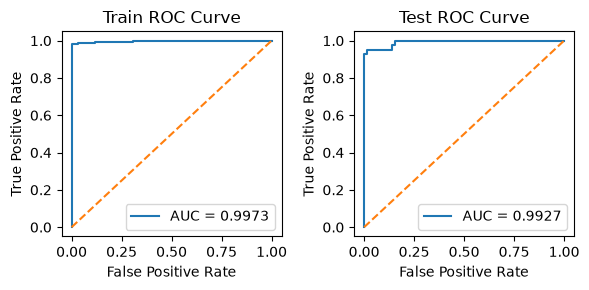

Train Confusion Matrix:
[[284   1]
 [  3 167]]
Test Confusion Matrix:
[[69  3]
 [ 2 40]]


In [32]:
fig, axes = plt.subplots(1, 2, figsize=(6,3))

for ax, split in zip(axes, ["Train", "Test"]):
    y_true, pred, scores = roc_data[split]

    fpr, tpr, _ = roc_curve(y_true, scores)
    auc = roc_auc_score(y_true, scores)

    ax.plot(fpr, tpr, label=f"AUC = {auc:.4f}")
    ax.plot([0, 1], [0, 1], "--")
    ax.set_title(f"{split} ROC Curve")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend()

plt.tight_layout()
plt.show()

for split in ["Train", "Test"]:
    y_true, pred, _ = roc_data[split]

    print(f"{split} Confusion Matrix:")
    print(confusion_matrix(y_true, pred))

### ii. Semi-Supervised Learning — Self-Training

#### A. L1-penalized SVM on the labeled data

In [5]:
C_grid = [0.001, 0.01, 0.1, 1, 10, 100]
metrics = ["Accuracy", "Precision", "Recall", "F1", "AUC"]

semi_runs = []      # everything part B needs, one entry per Monte Carlo run
A_results = []      # metrics of the SVM trained on the labeled half only
chosen_C, cv_auc = [], []

for i in range(30):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=i
    )

    # 50% of the positive class and 50% of the negative class are labeled
    X_l, X_u, y_l, _ = train_test_split(
        X_train, y_train, train_size=0.5, stratify=y_train, random_state=i
    )

    scaler = StandardScaler()
    X_l = scaler.fit_transform(X_l)
    X_u = scaler.transform(X_u)
    X_train_scaled = scaler.transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=i)
    grid = GridSearchCV(
        LinearSVC(penalty="l1", dual=False, max_iter=100000, tol=1e-3, random_state=42),
        {"C": C_grid}, cv=cv, scoring="roc_auc", n_jobs=-1
    )
    grid.fit(X_l, y_l)
    model = grid.best_estimator_
    chosen_C.append(grid.best_params_["C"])
    cv_auc.append(grid.best_score_)

    for split, X_part, y_part in [("Train", X_train_scaled, y_train),
                                  ("Test", X_test_scaled, y_test)]:
        pred = model.predict(X_part)
        scores = model.decision_function(X_part)
        A_results.append({
            "Run": i + 1, "Set": split,
            "Accuracy": accuracy_score(y_part, pred),
            "Precision": precision_score(y_part, pred),
            "Recall": recall_score(y_part, pred),
            "F1": f1_score(y_part, pred),
            "AUC": roc_auc_score(y_part, scores)
        })

    semi_runs.append({
        "model": model, "X_l": np.asarray(X_l), "y_l": np.asarray(y_l), "X_u": X_u,
        "X_train": X_train_scaled, "y_train": y_train.to_numpy(),
        "X_test": X_test_scaled, "y_test": y_test.to_numpy()
    })

A_df = pd.DataFrame(A_results)

print("Part A: penalty parameter C selected by 5-fold CV (number of runs out of 30)")
print(pd.Series(chosen_C).value_counts().sort_index().to_string())
print(f"\nMean 5-fold CV AUC of the selected C: {np.mean(cv_auc):.4f}")
print("\nAverage metrics of the SVM trained on the labeled half only (30 runs):")
print(A_df.groupby("Set")[metrics].mean().round(4))


Part A: penalty parameter C selected by 5-fold CV (number of runs out of 30)
0.1      15
1.0       6
10.0      1
100.0     8

Mean 5-fold CV AUC of the selected C: 0.9932

Average metrics of the SVM trained on the labeled half only (30 runs):
       Accuracy  Precision  Recall      F1     AUC
Set                                               
Test     0.9640     0.9614  0.9413  0.9508  0.9898
Train    0.9785     0.9793  0.9629  0.9709  0.9946


#### B. Self-training

In [6]:
semi_results = []
semi_roc_data = {}

for i, run in enumerate(semi_runs):
    model = copy.deepcopy(run["model"])          # start from the part-A SVM
    X_l, y_l = run["X_l"].copy(), run["y_l"].copy()
    X_u = run["X_u"].copy()

    while len(X_u) > 0:
        distances = np.abs(model.decision_function(X_u))
        idx = np.argmax(distances)                # farthest from the boundary

        x_new = X_u[idx:idx + 1]
        y_new = model.predict(x_new)              # label given by the SVM itself

        X_l = np.vstack([X_l, x_new])
        y_l = np.concatenate([y_l, y_new])
        X_u = np.delete(X_u, idx, axis=0)

        model.fit(X_l, y_l)                       # retrain

    for split, X_part, y_part in [("Train", run["X_train"], run["y_train"]),
                                  ("Test", run["X_test"], run["y_test"])]:
        pred = model.predict(X_part)
        scores = model.decision_function(X_part)

        semi_results.append({
            "Run": i + 1, "Set": split,
            "Accuracy": accuracy_score(y_part, pred),
            "Precision": precision_score(y_part, pred),
            "Recall": recall_score(y_part, pred),
            "F1": f1_score(y_part, pred),
            "AUC": roc_auc_score(y_part, scores)
        })

        if i == 0:
            semi_roc_data[split] = (y_part, pred, scores)

semi_results_df = pd.DataFrame(semi_results)

print("Part B: average metrics after self-training (30 runs):")
print(semi_results_df.groupby("Set")[metrics].mean().round(4))


Part B: average metrics after self-training (30 runs):
       Accuracy  Precision  Recall      F1     AUC
Set                                               
Test     0.9626     0.9656  0.9325  0.9483  0.9896
Train    0.9777     0.9787  0.9614  0.9698  0.9942


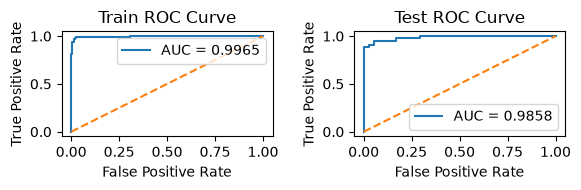

Train Confusion Matrix:
[[284   1]
 [ 12 158]]
Test Confusion Matrix:
[[70  2]
 [ 4 38]]


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(6,2))

for ax, split in zip(axes, ["Train", "Test"]):
    y_true, pred, scores = semi_roc_data[split]

    fpr, tpr, _ = roc_curve(y_true, scores)
    auc = roc_auc_score(y_true, scores)

    ax.plot(fpr, tpr, label=f"AUC = {auc:.4f}")
    ax.plot([0, 1], [0, 1], "--")
    ax.set_title(f"{split} ROC Curve")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend()

plt.tight_layout()
plt.show()

for split in ["Train", "Test"]:
    y_true, pred, _ = semi_roc_data[split]
    print(f"{split} Confusion Matrix:")
    print(confusion_matrix(y_true, pred))

In [8]:
A_test = A_df[A_df["Set"] == "Test"][metrics].mean()
B_test = semi_results_df[semi_results_df["Set"] == "Test"][metrics].mean()
S_test = results_df[results_df["Set"] == "Test"][metrics].mean()

print("Test-set comparison (average of 30 runs):")
print(pd.DataFrame({
    "A: labeled half only": A_test,
    "B: after self-training": B_test,
    "Fully supervised (part i)": S_test
}).T.round(4))

Test-set comparison (average of 30 runs):
                           Accuracy  Precision  Recall      F1     AUC
A: labeled half only         0.9640     0.9614  0.9413  0.9508  0.9898
B: after self-training       0.9626     0.9656  0.9325  0.9483  0.9896
Fully supervised (part i)    0.9678     0.9729  0.9397  0.9555  0.9932


### iii. Unsupervised Learning — K-Means

#### A. K-Means with Random Initialization

In [9]:
unsup_runs = []

for i in range(30):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=i
    )

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)

    kmeans = KMeans(
        n_clusters=2,
        init="random",
        n_init=20,
        random_state=i
    )

    clusters = kmeans.fit_predict(X_train_scaled)

    unsup_runs.append({
        "kmeans": kmeans,
        "X_train": X_train_scaled,
        "y_train": y_train.to_numpy(),
        "clusters": clusters
    })
print("Completed 30 Monte Carlo runs.")

Completed 30 Monte Carlo runs.


K-Means was run with `init="random"` and `n_init=20`: in every Monte Carlo run the algorithm is started from 20 different random initializations and the solution with the **lowest inertia** is kept. Since k-means only converges to a local minimum, a single random start can end in a bad solution; taking the best of many starts gives us a good chance that the clustering is not going to be trapped in a bad local minimum.

In [10]:
Xtr1 = unsup_runs[0]["X_train"]
inertias = np.array([
    KMeans(n_clusters=2, init="random", n_init=1, random_state=s).fit(Xtr1).inertia_
    for s in range(50)
])
best = unsup_runs[0]["kmeans"].inertia_
print(f"Inertia (n_init=20): {best:.4f}; {(np.isclose(inertias, best, rtol=1e-6)).sum()} of 50 single starts reached it")

Inertia (n_init=20): 9216.6769; 50 of 50 single starts reached it


#### B. Majority Voting and Evaluation

Average training metrics over 30 runs:
Accuracy     0.9103
Precision    0.9239
Recall       0.8284
F1           0.8734
AUC          0.9749
dtype: float64


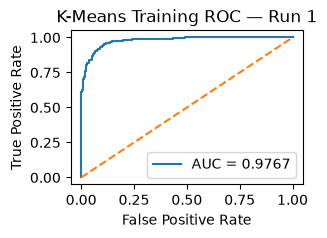

Training Confusion Matrix — Run 1:
[[277   8]
 [ 33 137]]


In [11]:


unsup_results = []
unsup_roc_data = None

for i, run in enumerate(unsup_runs):
    kmeans = run["kmeans"]
    X_train_scaled = run["X_train"]
    y_train = run["y_train"]
    clusters = run["clusters"]

    distances = kmeans.transform(X_train_scaled)
    cluster_labels = {}

    for c in range(2):
        closest_idx = np.argsort(distances[:, c])[:30]
        cluster_labels[c] = np.bincount(
            y_train[closest_idx], minlength=2
        ).argmax()

    y_pred = np.array([cluster_labels[c] for c in clusters])

    # Scores based on relative distances to cluster centers
    if set(cluster_labels.values()) == {0, 1}:
        pos_cluster = next(c for c in range(2) if cluster_labels[c] == 1)
        neg_cluster = 1 - pos_cluster
        scores = distances[:, neg_cluster] - distances[:, pos_cluster]
    else:
        scores = np.full(len(y_train), cluster_labels[0], dtype=float)

    unsup_results.append({
        "Run": i + 1,
        "Accuracy": accuracy_score(y_train, y_pred),
        "Precision": precision_score(y_train, y_pred, zero_division=0),
        "Recall": recall_score(y_train, y_pred, zero_division=0),
        "F1": f1_score(y_train, y_pred, zero_division=0),
        "AUC": roc_auc_score(y_train, scores)
    })

    if i == 0:
        unsup_roc_data = (y_train, y_pred, scores)

unsup_results_df = pd.DataFrame(unsup_results)

print("Average training metrics over 30 runs:")
print(
    unsup_results_df[
        ["Accuracy", "Precision", "Recall", "F1", "AUC"]
    ].mean().round(4)
)

# ROC and confusion matrix for Run 1
y_true, y_pred, scores = unsup_roc_data

fpr, tpr, _ = roc_curve(y_true, scores)

plt.figure(figsize=(3,2))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_true, scores):.4f}")
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("K-Means Training ROC — Run 1")
plt.legend()
plt.show()

print("Training Confusion Matrix — Run 1:")
print(confusion_matrix(y_true, y_pred))

#### C. K-Means Test Data Classification

Average test metrics over 30 runs:
Accuracy     0.9053
Precision    0.9096
Recall       0.8262
F1           0.8647
AUC          0.9719
dtype: float64


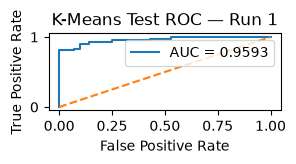

Test Confusion Matrix — Run 1:
[[65  7]
 [ 7 35]]


In [31]:
test_results = []
test_roc_data = None

for i, run in enumerate(unsup_runs):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=i
    )

    scaler = StandardScaler()
    scaler.fit(X_train)
    X_test_scaled = scaler.transform(X_test)

    kmeans = run["kmeans"]
    distances_train = kmeans.transform(run["X_train"])

    cluster_labels = {}
    for c in range(2):
        closest_idx = np.argsort(distances_train[:, c])[:30]
        cluster_labels[c] = np.bincount(
            run["y_train"][closest_idx], minlength=2
        ).argmax()

    distances_test = kmeans.transform(X_test_scaled)
    test_clusters = kmeans.predict(X_test_scaled)

    y_pred = np.array([cluster_labels[c] for c in test_clusters])

    if set(cluster_labels.values()) == {0, 1}:
        pos = next(c for c in range(2) if cluster_labels[c] == 1)
        neg = 1 - pos
        scores = distances_test[:, neg] - distances_test[:, pos]
    else:
        scores = np.full(len(y_test), cluster_labels[0], dtype=float)

    test_results.append({
        "Run": i + 1,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "AUC": roc_auc_score(y_test, scores)
    })

    if i == 0:
        test_roc_data = (y_test, y_pred, scores)

test_results_df = pd.DataFrame(test_results)

print("Average test metrics over 30 runs:")
print(
    test_results_df[
        ["Accuracy", "Precision", "Recall", "F1", "AUC"]
    ].mean().round(4)
)

# ROC curve and confusion matrix for Run 1
y_true, y_pred, scores = test_roc_data

fpr, tpr, _ = roc_curve(y_true, scores)

plt.figure(figsize=(3,1))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_true, scores):.4f}")
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("K-Means Test ROC — Run 1")
plt.legend()
plt.show()

print("Test Confusion Matrix — Run 1:")
print(confusion_matrix(y_true, y_pred))

### iv. Spectral Clustering

**What it is.** Spectral clustering builds a similarity graph on the data with a kernel (here the RBF kernel $K(x,x')=\exp(-\gamma\|x-x'\|^2)$), forms the graph Laplacian, and represents every point by the eigenvectors of the Laplacian that belong to its smallest eigenvalues (two of them for $k=2$). The points are then clustered in this spectral embedding. Because it uses the connectivity of the graph rather than the distance to a center, it can find non-convex clusters; but it has no cluster centers and no `predict` method.

In [13]:
p = int(y.sum())               # positive class (M)
n_neg = int((1 - y).sum())     # negative class (B)
print(f"Original data: positive (M) = {p}, negative (B) = {n_neg}")

X_all_scaled = StandardScaler().fit_transform(X)       # features only; labels are not used
gamma_grid = np.concatenate([[1.0], np.logspace(-6, -1.5, 120)])

rows = []
for g in gamma_grid:
    cl = SpectralClustering(n_clusters=2, affinity="rbf", gamma=g,
                            assign_labels="discretize", random_state=0).fit_predict(X_all_scaled)
    sizes = np.sort(np.bincount(cl, minlength=2))
    rows.append({"gamma": g, "smaller cluster": sizes[0], "larger cluster": sizes[1],
                 "|smaller - p|": abs(sizes[0] - p)})
gamma_table = pd.DataFrame(rows)
print(gamma_table.iloc[np.linspace(0, len(gamma_table) - 1, 5).astype(int)].to_string(index=False, float_format=lambda v: f"{v:.6f}"))   # every 6th row for brevity

# among the gammas with the best balance, take the largest (numerically most stable)
best_gap = gamma_table["|smaller - p|"].min()
GAMMA = gamma_table.loc[gamma_table["|smaller - p|"] == best_gap, "gamma"].max()
print(f"\nSelected gamma = {GAMMA:.5f}")
sel = gamma_table.loc[gamma_table["gamma"] == GAMMA].iloc[0]
print(f"Cluster sizes at the selected gamma: {int(sel['smaller cluster'])} / {int(sel['larger cluster'])}  (original classes: {p} / {n_neg})")
print("Exact class balance reached:", best_gap == 0)
print("Smallest-cluster sizes reachable on the whole grid:", sorted(gamma_table["smaller cluster"].unique())[-6:])


Original data: positive (M) = 212, negative (B) = 357
   gamma  smaller cluster  larger cluster  |smaller - p|
1.000000                2             567            210
0.000012              202             367             10
0.000170              202             367             10
0.002320              199             370             13
0.031623                2             567            210

Selected gamma = 0.00031
Cluster sizes at the selected gamma: 202 / 367  (original classes: 212 / 357)
Exact class balance reached: False
Smallest-cluster sizes reachable on the whole grid: [np.int64(197), np.int64(198), np.int64(199), np.int64(200), np.int64(201), np.int64(202)]


In [14]:
spectral_results, spectral_test_results = [], []
spectral_roc = {}

for i in range(30):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=i
    )

    scaler = StandardScaler().fit(X_train)
    X_all = np.vstack([scaler.transform(X_train), scaler.transform(X_test)])
    n_tr = len(X_train)
    y_tr, y_te = y_train.to_numpy(), y_test.to_numpy()

    # TRANSDUCTIVE: fit_predict on training + test *features* together (no labels are used here);
    # SpectralClustering has no predict(), so test points cannot be clustered after fitting.
    clusters = SpectralClustering(
        n_clusters=2, affinity="rbf", gamma=GAMMA,
        assign_labels="discretize", random_state=i
    ).fit_predict(X_all)

    # label each cluster by majority poll of 30 randomly selected training points
    rng = np.random.default_rng(i)
    cluster_label = {}
    for c in range(2):
        members = np.where(clusters[:n_tr] == c)[0]
        pick = rng.choice(members, size=min(30, len(members)), replace=False)
        cluster_label[c] = np.bincount(y_tr[pick], minlength=2).argmax()

    pred = np.array([cluster_label[c] for c in clusters])

    # score for the ROC: mean RBF similarity to each cluster
    K = rbf_kernel(X_all, X_all, gamma=GAMMA)
    sim = np.column_stack([K[:, clusters == c].mean(axis=1) for c in range(2)])
    if set(cluster_label.values()) == {0, 1}:
        pos = next(c for c in range(2) if cluster_label[c] == 1)
        scores = sim[:, pos] - sim[:, 1 - pos]
    else:
        scores = np.zeros(len(X_all))

    for store, yt, yp, sc in [
        (spectral_results, y_tr, pred[:n_tr], scores[:n_tr]),
        (spectral_test_results, y_te, pred[n_tr:], scores[n_tr:])
    ]:
        store.append({
            "Run": i + 1,
            "Accuracy": accuracy_score(yt, yp),
            "Precision": precision_score(yt, yp, zero_division=0),
            "Recall": recall_score(yt, yp, zero_division=0),
            "F1": f1_score(yt, yp, zero_division=0),
            "AUC": roc_auc_score(yt, sc)
        })

    if i == 0:
        spectral_roc["Train"] = (y_tr, pred[:n_tr], scores[:n_tr])
        spectral_roc["Test"] = (y_te, pred[n_tr:], scores[n_tr:])
        print("Run 1 cluster sizes:", np.bincount(clusters), "| cluster -> label:", cluster_label)

spectral_results_df = pd.DataFrame(spectral_results)
spectral_test_results_df = pd.DataFrame(spectral_test_results)

print("\nAverage Training Metrics (30 runs):")
print(spectral_results_df[metrics].mean().round(4))
print("\nAverage Testing Metrics (30 runs):")
print(spectral_test_results_df[metrics].mean().round(4))


Run 1 cluster sizes: [368 201] | cluster -> label: {0: np.int64(0), 1: np.int64(1)}

Average Training Metrics (30 runs):
Accuracy     0.9148
Precision    0.9094
Recall       0.8575
F1           0.8826
AUC          0.9710
dtype: float64

Average Testing Metrics (30 runs):
Accuracy     0.9123
Precision    0.8949
Recall       0.8651
F1           0.8788
AUC          0.9686
dtype: float64


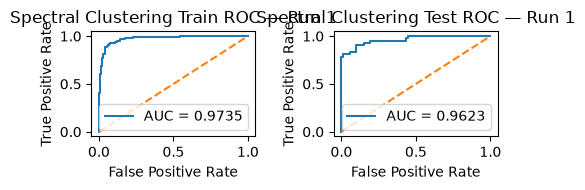

Train Confusion Matrix — Run 1 (rows = true B/M, columns = predicted B/M):
[[273  12]
 [ 26 144]]
Test Confusion Matrix — Run 1 (rows = true B/M, columns = predicted B/M):
[[65  7]
 [ 4 38]]


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(5,2))

for ax, split in zip(axes, ["Train", "Test"]):
    y_true, pred, scores = spectral_roc[split]
    fpr, tpr, _ = roc_curve(y_true, scores)
    ax.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_true, scores):.4f}")
    ax.plot([0, 1], [0, 1], "--")
    ax.set_title(f"Spectral Clustering {split} ROC — Run 1")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend()

plt.tight_layout()
plt.show()

for split in ["Train", "Test"]:
    y_true, pred, _ = spectral_roc[split]
    print(f"{split} Confusion Matrix — Run 1 (rows = true B/M, columns = predicted B/M):")
    print(confusion_matrix(y_true, pred))


### v. Comparison of Supervised, Semi-Supervised, and Unsupervised Learning

In [16]:
metrics = ["Accuracy", "Precision", "Recall", "F1", "AUC"]

test_tbl = pd.DataFrame({
    "Supervised": results_df[results_df["Set"] == "Test"][metrics].mean(),
    "Semi-Supervised": semi_results_df[semi_results_df["Set"] == "Test"][metrics].mean(),
    "K-Means": test_results_df[metrics].mean(),
    "Spectral Clustering": spectral_test_results_df[metrics].mean()
}).T

train_tbl = pd.DataFrame({
    "Supervised": results_df[results_df["Set"] == "Train"][metrics].mean(),
    "Semi-Supervised": semi_results_df[semi_results_df["Set"] == "Train"][metrics].mean(),
    "K-Means": unsup_results_df[metrics].mean(),
    "Spectral Clustering": spectral_results_df[metrics].mean()
}).T

comparison = test_tbl
print("TEST SET — average over 30 runs")
print(test_tbl.round(4))
print("\nTRAINING SET — average over 30 runs")
print(train_tbl.round(4))

TEST SET — average over 30 runs
                     Accuracy  Precision  Recall      F1     AUC
Supervised             0.9678     0.9729  0.9397  0.9555  0.9932
Semi-Supervised        0.9626     0.9656  0.9325  0.9483  0.9896
K-Means                0.9053     0.9096  0.8262  0.8647  0.9719
Spectral Clustering    0.9123     0.8949  0.8651  0.8788  0.9686

TRAINING SET — average over 30 runs
                     Accuracy  Precision  Recall      F1     AUC
Supervised             0.9866     0.9912  0.9727  0.9819  0.9975
Semi-Supervised        0.9777     0.9787  0.9614  0.9698  0.9942
K-Means                0.9103     0.9239  0.8284  0.8734  0.9749
Spectral Clustering    0.9148     0.9094  0.8575  0.8826  0.9710


In [17]:
t = test_tbl
sup, semi, km, sp = t.loc["Supervised"], t.loc["Semi-Supervised"], t.loc["K-Means"], t.loc["Spectral Clustering"]

# paired comparison of test accuracy, supervised vs semi-supervised, over the 30 runs
d = (results_df[results_df["Set"] == "Test"]["Accuracy"].to_numpy()
     - semi_results_df[semi_results_df["Set"] == "Test"]["Accuracy"].to_numpy())
wins, ties, losses = int((d > 0).sum()), int((d == 0).sum()), int((d < 0).sum())

best_on = [m for m in metrics if t[m].idxmax() == "Supervised"]
km_wins = [m for m in metrics if km[m] > sp[m]]
sp_wins = [m for m in metrics if sp[m] > km[m]]
g1 = gamma_table.iloc[0]

**Test-set averages over 30 runs.**
| Method | Accuracy | AUC | Recall |
|---|---|---|---|
| Supervised SVM | 0.9678 | 0.9932 | 0.9397 |
| Semi-supervised SVM | 0.9626 | 0.9896 | 0.9325 |
| K-means | 0.9053 | 0.9719 | 0.8262 |
| Spectral clustering | 0.9123 | 0.9686 | 0.8651 |
**Supervised vs. semi-supervised:** Supervised SVM is better by 0.0053 in accuracy and wins in 15 of 30 runs, while semi-supervised remains competitive using only half the labels.
**Supervised vs. unsupervised:** K-means and spectral clustering are lower in accuracy by 0.0626 and 0.0556, and in recall by 0.1135 and 0.0746 (more missed malignant cases).
**K-means vs. spectral:** 0.9053 accuracy / 0.9719 AUC vs. 0.9123 / 0.9686. Neither wins on every metric.
Overall, supervised learning performs best, semi-supervised is similar with fewer labels, and unsupervised is worse because it does not use labels.

### 2(a) Banknote Authentication Dataset

In [18]:

banknote = pd.read_csv("../data/data_banknote_authentication.txt", header=None)
print(banknote.shape)            # should be (1372, 5)

X_bank, y_bank = banknote.iloc[:, :-1], banknote.iloc[:, -1]
X_train_bank, X_test_bank, y_train_bank, y_test_bank = train_test_split(
    X_bank, y_bank, train_size=900, test_size=472, random_state=42, shuffle=True)

X_pool = X_train_bank.to_numpy();  y_pool = y_train_bank.to_numpy().astype(int)
X_test = X_test_bank.to_numpy();   y_test = y_test_bank.to_numpy().astype(int)


(1372, 5)


### 2(b) Passive and Active Learning — setup

In [19]:
C_values = [0.01, 0.1, 1, 10]

def train_svm(X_l, y_l):
    """L1-penalized linear SVM (LinearSVC, penalty='l1', dual=False); C chosen by 5-fold CV."""
    import warnings; warnings.filterwarnings("ignore")
    pipe = Pipeline([("scaler", StandardScaler()),
                     ("svm", LinearSVC(penalty="l1", dual=False, max_iter=100_000, tol=1e-3, random_state=42))])
    n_splits = min(5, np.bincount(y_l, minlength=2).min())
    if n_splits < 2:
        return pipe.fit(X_l, y_l)
    grid = GridSearchCV(pipe, {"svm__C": C_values},
                        cv=StratifiedKFold(n_splits, shuffle=True, random_state=42),
                        scoring="accuracy", n_jobs=1)
    return grid.fit(X_l, y_l).best_estimator_

def start_indices(run):
    """Random permutation whose first 10 points contain both classes."""
    rng = np.random.default_rng(run)
    while True:
        idx = rng.permutation(len(X_pool))
        if len(np.unique(y_pool[idx[:10]])) == 2:
            return idx


In [20]:
# Footnote 4: training accuracy of the L1-penalized linear SVM for very small / very large C on the full pool
Xs_pool = StandardScaler().fit_transform(X_pool)
for C in [1e-3, 1e-2, 1e-1, 1, 10, 100]:
    svm = LinearSVC(penalty="l1", dual=False, C=C, max_iter=100_000, tol=1e-3, random_state=42).fit(Xs_pool, y_pool)
    print(f"C = {C:<6} training accuracy = {svm.score(Xs_pool, y_pool):.4f}")


C = 0.001  training accuracy = 0.8544
C = 0.01   training accuracy = 0.9678
C = 0.1    training accuracy = 0.9822
C = 1      training accuracy = 0.9911
C = 10     training accuracy = 0.9878
C = 100    training accuracy = 0.9922


#### i. Passive learning

In [21]:
def passive_run(run):
    idx = start_indices(run); errs = np.zeros(90)
    for s in range(90):
        sel = idx[:(s + 1) * 10]
        m = train_svm(X_pool[sel], y_pool[sel])
        errs[s] = zero_one_loss(y_test, m.predict(X_test))
    return errs

passive_errors = np.array(Parallel(n_jobs=-1, verbose=5)(
    delayed(passive_run)(r) for r in range(50)))


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 tasks      | elapsed:    5.0s
[Parallel(n_jobs=-1)]: Done  46 out of  50 | elapsed:   31.4s remaining:    2.7s
[Parallel(n_jobs=-1)]: Done  50 out of  50 | elapsed:   34.3s finished


#### ii. Active learning

In [22]:
def active_run(run):
    idx = start_indices(run)
    selected, remaining = idx[:10].tolist(), idx[10:].copy()
    errs = np.zeros(90)
    for s in range(90):
        m = train_svm(X_pool[selected], y_pool[selected])
        errs[s] = zero_one_loss(y_test, m.predict(X_test))
        if s == 89:
            break
        dist = np.abs(m.decision_function(X_pool[remaining]))
        closest = np.argsort(dist)[:10]
        selected.extend(remaining[closest].tolist())
        remaining = np.delete(remaining, closest)
    return errs

active_errors = np.array(Parallel(n_jobs=-1, verbose=5)(
    delayed(active_run)(r) for r in range(50)))


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 tasks      | elapsed:    6.2s
[Parallel(n_jobs=-1)]: Done  46 out of  50 | elapsed:   38.2s remaining:    3.3s
[Parallel(n_jobs=-1)]: Done  50 out of  50 | elapsed:   41.9s finished


### 2(c) Monte Carlo Learning Curves

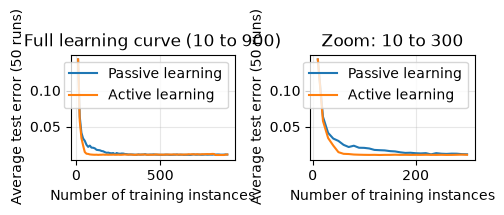

 Size  Passive  Active  Passive - Active
   10   0.1432  0.1432            0.0000
   20   0.0636  0.0578            0.0058
   30   0.0414  0.0342            0.0071
   50   0.0303  0.0147            0.0156
  100   0.0206  0.0110            0.0097
  200   0.0132  0.0110            0.0022
  300   0.0117  0.0111            0.0007
  500   0.0109  0.0111           -0.0002
  900   0.0112  0.0113           -0.0000
Passive reaches within 0.01 of final error at n = 90
Active reaches within 0.01 of final error at n = 50


In [30]:
sizes = np.arange(10, 901, 10)
pm, am = passive_errors.mean(axis=0), active_errors.mean(axis=0)   # average over 50 runs

fig, ax = plt.subplots(1, 2, figsize=(5,2))
for a, xmax in zip(ax, [900, 300]):
    k = sizes <= xmax
    a.plot(sizes[k], pm[k], label="Passive learning")
    a.plot(sizes[k], am[k], label="Active learning")
    a.set_xlabel("Number of training instances")
    a.set_ylabel("Average test error (50 runs)")
    a.grid(alpha=.3); a.legend()
ax[0].set_title("Full learning curve (10 to 900)")
ax[1].set_title("Zoom: 10 to 300")
plt.tight_layout(); plt.show()

# numbers to cite in the write-up
summary = pd.DataFrame({"Size": sizes, "Passive": pm, "Active": am, "Passive - Active": pm - am})
print(summary[summary["Size"].isin([10, 20, 30, 50, 100, 200, 300, 500, 900])].round(4).to_string(index=False))

# first size where each learner gets within 0.01 of its final error
for name, curve in [("Passive", pm), ("Active", am)]:
    print(name, "reaches within 0.01 of final error at n =", sizes[np.argmax(curve <= curve[-1] + 0.01)])

In [24]:
gap = pm - am                                             # > 0: active learning has the lower error
se = (passive_errors - active_errors).std(axis=0, ddof=1) / np.sqrt(passive_errors.shape[0])

def as_ranges(v):
    v = list(v); out = []
    for k, x in enumerate(v):
        if out and x - out[-1][1] == 10:
            out[-1][1] = x
        else:
            out.append([x, x])
    return ", ".join(f"{a}-{b}" if a != b else f"{a}" for a, b in out) or "none"

print("Sizes where active is better by more than 2 standard errors:", as_ranges(sizes[gap > 2 * se]))
print("Sizes where active is worse  by more than 2 standard errors:", as_ranges(sizes[gap < -2 * se]))
print()
for lo, hi in [(10, 30), (40, 100), (110, 300), (310, 900)]:
    k = (sizes >= lo) & (sizes <= hi)
    print(f"mean error for n = {lo:>3}..{hi:<3}: passive {pm[k].mean():.4f}   active {am[k].mean():.4f}")
print(f"\nFinal error at n = 900: passive {pm[-1]:.4f}, active {am[-1]:.4f}  (1 test error = {1/len(y_test):.4f})")


Sizes where active is better by more than 2 standard errors: 50-220, 240-280, 410, 830-880
Sizes where active is worse  by more than 2 standard errors: 640, 660-690, 720, 740-760, 780-820

mean error for n =  10..30 : passive 0.0827   active 0.0784
mean error for n =  40..100: passive 0.0251   active 0.0138
mean error for n = 110..300: passive 0.0142   active 0.0110
mean error for n = 310..900: passive 0.0111   active 0.0112

Final error at n = 900: passive 0.0112, active 0.0113  (1 test error = 0.0021)


#### Conclusions

The results are based on the **L1-penalized linear SVM**, averaged over 50 Monte Carlo runs.

- **Initial and final performance:** Both methods start with the same 10 labeled points (error ≈ 0.143) and converge to approximately 0.011 at n = 900.

- **Small training sets (n = 20–30):** Active learning performs slightly better, with errors of 0.057 vs. 0.064 at n = 20 and 0.033 vs. 0.041 at n = 30. However, the differences are small and not statistically significant.

- **Moderate training sets (n = 50–220):** Active learning shows its greatest advantage. At n = 50, its error is 0.0142 compared with 0.0303 for passive learning. At n = 100, the errors are 0.0110 vs. 0.0206. Selecting points near the decision boundary helps the SVM learn efficiently with fewer labeled examples.

- **Large training sets (n ≥ 300):** The performance gap becomes very small (0.0007 at n = 300), and both methods eventually achieve nearly identical results as more training data becomes available.

**Overall:** Active learning is more label-efficient than passive learning, particularly with 50–200 training examples. However, as the training set grows, their performance converges because both models eventually learn similar decision boundaries.